# Đánh giá mô hình & ma trận nhầm lẫn

Mỗi kỳ test được biến thành bài toán phân loại nhị phân cho từng số:
nhãn `1` nếu số đó xuất hiện trong kỳ, `0` nếu không. Ma trận nhầm lẫn
được tính bằng cách gộp tất cả cặp (kỳ, số) của tập test.

Hai cách ra quyết định được phân tích:

1. **Theo ngưỡng xác suất** (mặc định 0.5) — phù hợp để xem mô hình có
   hiệu chuẩn tốt không. Vì xác suất trúng rất thấp (~`k/F`), ngưỡng 0.5
   thường dự đoán toàn âm; điều này là bình thường.
2. **Theo top-k** — chọn `k` số có xác suất cao nhất mỗi kỳ, đúng với
   cách dùng thực tế của mô hình.

> Nếu mô hình chưa được lưu, notebook sẽ tự huấn luyện (chậm hơn). Chạy
> `python -m vietlott_ml.cli train --lottery all` trước để dùng mô hình sẵn có.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from vietlott_ml.config import (
    LOTTERIES,
    TRAIN_RATIO,
    WINDOW_SIZE,
    lottery_config,
)
from vietlott_ml.models import (
    DISPLAY_NAMES,
    MODEL_NAMES,
    SEQUENCE_MODELS,
    TABULAR_MODELS,
    load_model,
    model_path,
)
from vietlott_ml.training import (
    _fit_predict_markov,
    _fit_predict_sequence,
    _fit_predict_tabular,
    _prepare,
)

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid")
print("Repo:", ROOT)

Repo: /mnt/d/Vietlott_VN


## 1. Chuẩn bị dữ liệu test và xác suất dự đoán

`_prepare` tái sử dụng đúng logic chia train/test theo thời gian của
pipeline, nên kết quả khớp với `reports/*_metrics.json`.

In [2]:
PREPARED = {}

def prepared(lottery: str):
    if lottery not in PREPARED:
        PREPARED[lottery] = _prepare(lottery, WINDOW_SIZE, TRAIN_RATIO)
    return PREPARED[lottery]


def test_probabilities(lottery: str, name: str):
    data = prepared(lottery)
    if model_path(lottery, name).exists():
        model = load_model(lottery, name)
        if name in SEQUENCE_MODELS:
            probs = model.predict_proba(data.X_seq_test)
        elif name == "mlp":
            probs = model.predict_proba(data.X_last_test)
        elif name in TABULAR_MODELS:
            probs = model.predict_proba(
                data.X_tab_test_samples.reshape(-1, data.tabular.X.shape[-1])
            )
        elif name == "markov":
            probs = model.predict_proba(data.matrix, data.test_targets)
        else:
            raise ValueError(name)
        source = "saved"
    else:
        if name in SEQUENCE_MODELS or name == "mlp":
            probs, _ = _fit_predict_sequence(name, data, WINDOW_SIZE, False)
        elif name in TABULAR_MODELS:
            probs, _ = _fit_predict_tabular(name, data, False)
        elif name == "markov":
            probs, _ = _fit_predict_markov(data, False)
        else:
            raise ValueError(name)
        source = "trained now"
    return probs, source

In [3]:
PROBS = {}
TRUTH = {}

for lottery in LOTTERIES:
    data = prepared(lottery)
    TRUTH[lottery] = np.stack([data.matrix[t] for t in data.test_targets])
    print(
        f"{LOTTERIES[lottery]['name']}: "
        f"{len(data.test_targets)} kỳ test, "
        f"{TRUTH[lottery].size:,} cặp (kỳ, số)"
    )
    for name in MODEL_NAMES:
        probs, source = test_probabilities(lottery, name)
        PROBS[(lottery, name)] = probs
        print(f"  {name:14s} probs={probs.shape} ({source})")

Mega 6/45: 272 kỳ test, 12,240 cặp (kỳ, số)


  lstm           probs=(272, 45) (saved)
  bilstm         probs=(272, 45) (saved)
  logistic       probs=(272, 45) (saved)


  random_forest  probs=(272, 45) (saved)
  markov         probs=(272, 45) (saved)
  mlp            probs=(272, 45) (saved)


  xgboost        probs=(272, 45) (saved)
Power 6/55: 279 kỳ test, 15,345 cặp (kỳ, số)
  lstm           probs=(279, 55) (saved)


  bilstm         probs=(279, 55) (saved)
  logistic       probs=(279, 55) (saved)


  random_forest  probs=(279, 55) (saved)
  markov         probs=(279, 55) (saved)
  mlp            probs=(279, 55) (saved)


  xgboost        probs=(279, 55) (saved)


## 2. Hàm tính ma trận nhầm lẫn

Bố cục chuẩn: hàng là **thực tế**, cột là **dự đoán**.

|            | Dự âm (0) | Dự dương (1) |
|------------|-----------|--------------|
| Thực âm (0) | TN        | FP           |
| Thực dương (1) | FN     | TP           |

In [4]:
def binary_confusion(y_true, y_score, threshold: float = 0.5) -> pd.DataFrame:
    y_true = np.asarray(y_true).ravel().astype(int)
    y_pred = (np.asarray(y_score).ravel() >= threshold).astype(int)
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    return pd.DataFrame(
        [[tn, fp], [fn, tp]],
        index=pd.Index(["Thực âm (0)", "Thực dương (1)"], name="Thực tế"),
        columns=pd.Index(["Dự âm (0)", "Dự dương (1)"], name="Dự đoán"),
    )


def confusion_metrics(cm: pd.DataFrame) -> dict:
    tn, fp = int(cm.iloc[0, 0]), int(cm.iloc[0, 1])
    fn, tp = int(cm.iloc[1, 0]), int(cm.iloc[1, 1])
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    specificity = tn / (tn + fp) if tn + fp else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall
        else 0.0
    )
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    return {
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "tn": tn,
        "precision": precision,
        "recall": recall,
        "specificity": specificity,
        "f1": f1,
        "accuracy": accuracy,
    }

## 3. Ma trận nhầm lẫn theo ngưỡng 0.5

Vì lớp dương rất hiếm (`k/F ≈ 0.11–0.13`), mô hình hiệu chuẩn tốt sẽ
cho xác suất dưới 0.5 gần như mọi cặp → dự đoán toàn âm. Khi đó
`accuracy` cao nhưng `recall = 0`: **accuracy là chỉ số gây nhầm lẫn**
trong bài toán mất cân bằng này.

In [5]:
rows = []
for lottery in LOTTERIES:
    for name in MODEL_NAMES:
        cm = binary_confusion(TRUTH[lottery], PROBS[(lottery, name)], 0.5)
        m = confusion_metrics(cm)
        rows.append(
            {
                "lottery": LOTTERIES[lottery]["name"],
                "model": DISPLAY_NAMES[name],
                **m,
            }
        )

threshold_summary = pd.DataFrame(rows)
threshold_summary.round(4)

,lottery,model,tp,fp,fn,tn,precision,recall,specificity,f1,accuracy
0,Mega 6/45,LSTM,0,0,1632,10608,0.0000,0.0000,1.0000,0.0000,0.8667
1,Mega 6/45,BiLSTM,0,0,1632,10608,0.0000,0.0000,1.0000,0.0000,0.8667
2,Mega 6/45,Logistic Regression,716,4798,916,5810,0.1299,0.4387,0.5477,0.2004,0.5332
3,Mega 6/45,Random Forest,292,1997,1340,8611,0.1276,0.1789,0.8117,0.1489,0.7274
4,Mega 6/45,Markov,0,0,1632,10608,0.0000,0.0000,1.0000,0.0000,0.8667
5,Mega 6/45,MLP,0,0,1632,10608,0.0000,0.0000,1.0000,0.0000,0.8667
6,Mega 6/45,XGBoost,425,2796,1207,7812,0.1319,0.2604,0.7364,0.1751,0.6730
7,Power 6/55,LSTM,0,0,1674,13671,0.0000,0.0000,1.0000,0.0000,0.8909
8,Power 6/55,BiLSTM,0,0,1674,13671,0.0000,0.0000,1.0000,0.0000,0.8909
9,Power 6/55,Logistic Regression,751,6203,923,7468,0.1080,0.4486,0.5463,0.1741,0.5356


In [6]:
lottery = "mega645"
for name in MODEL_NAMES:
    cm = binary_confusion(TRUTH[lottery], PROBS[(lottery, name)], 0.5)
    print(f"### {LOTTERIES[lottery]['name']} — {DISPLAY_NAMES[name]}")
    display(cm)

### Mega 6/45 — LSTM


Dự đoán,Dự âm (0),Dự dương (1)
Thực tế,,
Thực âm (0),10608,0
Thực dương (1),1632,0


### Mega 6/45 — BiLSTM


Dự đoán,Dự âm (0),Dự dương (1)
Thực tế,,
Thực âm (0),10608,0
Thực dương (1),1632,0


### Mega 6/45 — Logistic Regression


Dự đoán,Dự âm (0),Dự dương (1)
Thực tế,,
Thực âm (0),5810,4798
Thực dương (1),916,716


... (4 outputs left out)

### Mega 6/45 — MLP


Dự đoán,Dự âm (0),Dự dương (1)
Thực tế,,
Thực âm (0),10608,0
Thực dương (1),1632,0


### Mega 6/45 — XGBoost


Dự đoán,Dự âm (0),Dự dương (1)
Thực tế,,
Thực âm (0),7812,2796
Thực dương (1),1207,425


## 4. Ma trận nhầm lẫn theo top-k

Đây là cách mô hình được dùng thực tế: mỗi kỳ chọn `k` số có xác suất
cao nhất làm dự đoán dương. Precision và recall kỳ vọng của chọn ngẫu
nhiên đều bằng `k/F`.

In [7]:
def topk_prediction(y_score, k: int) -> np.ndarray:
    y_score = np.asarray(y_score)
    pred = np.zeros_like(y_score, dtype=int)
    for i, row in enumerate(y_score):
        pred[i, np.argsort(-row, kind="stable")[:k]] = 1
    return pred


rows = []
for lottery in LOTTERIES:
    cfg = lottery_config(lottery)
    k = cfg["pick"]
    random_precision = k / cfg["n_features"]
    for name in MODEL_NAMES:
        pred = topk_prediction(PROBS[(lottery, name)], k)
        cm = binary_confusion(TRUTH[lottery], pred, 0.5)
        m = confusion_metrics(cm)
        rows.append(
            {
                "lottery": cfg["name"],
                "model": DISPLAY_NAMES[name],
                "random_precision": random_precision,
                "lift_precision": m["precision"] / random_precision,
                **m,
            }
        )

topk_summary = pd.DataFrame(rows)
topk_summary.round(4)

,lottery,model,random_precision,lift_precision,tp,fp,fn,tn,precision,recall,specificity,f1,accuracy
0,Mega 6/45,LSTM,0.1333,0.9329,203,1429,1429,9179,0.1244,0.1244,0.8653,0.1244,0.7665
1,Mega 6/45,BiLSTM,0.1333,1.0294,224,1408,1408,9200,0.1373,0.1373,0.8673,0.1373,0.7699
2,Mega 6/45,Logistic Regression,0.1333,0.9972,217,1415,1415,9193,0.1330,0.1330,0.8666,0.1330,0.7688
3,Mega 6/45,Random Forest,0.1333,0.9559,208,1424,1424,9184,0.1275,0.1275,0.8658,0.1275,0.7673
4,Mega 6/45,Markov,0.1333,1.0018,218,1414,1414,9194,0.1336,0.1336,0.8667,0.1336,0.7690
5,Mega 6/45,MLP,0.1333,0.9421,205,1427,1427,9181,0.1256,0.1256,0.8655,0.1256,0.7668
6,Mega 6/45,XGBoost,0.1333,0.9513,207,1425,1425,9183,0.1268,0.1268,0.8657,0.1268,0.7672
7,Power 6/55,LSTM,0.1091,0.9692,177,1497,1497,12174,0.1057,0.1057,0.8905,0.1057,0.8049
8,Power 6/55,BiLSTM,0.1091,1.0733,196,1478,1478,12193,0.1171,0.1171,0.8919,0.1171,0.8074
9,Power 6/55,Logistic Regression,0.1091,0.9200,168,1506,1506,12165,0.1004,0.1004,0.8898,0.1004,0.8037


In [8]:
lottery = "mega645"
k = lottery_config(lottery)["pick"]
for name in MODEL_NAMES:
    pred = topk_prediction(PROBS[(lottery, name)], k)
    cm = binary_confusion(TRUTH[lottery], pred, 0.5)
    print(f"### {LOTTERIES[lottery]['name']} — {DISPLAY_NAMES[name]} (top-{k})")
    display(cm)

### Mega 6/45 — LSTM (top-6)


Dự đoán,Dự âm (0),Dự dương (1)
Thực tế,,
Thực âm (0),9179,1429
Thực dương (1),1429,203


### Mega 6/45 — BiLSTM (top-6)


Dự đoán,Dự âm (0),Dự dương (1)
Thực tế,,
Thực âm (0),9200,1408
Thực dương (1),1408,224


### Mega 6/45 — Logistic Regression (top-6)

Dự đoán,Dự âm (0),Dự dương (1)
Thực tế,,
Thực âm (0),9193,1415
Thực dương (1),1415,217


... (4 outputs left out)

### Mega 6/45 — MLP (top-6)


Dự đoán,Dự âm (0),Dự dương (1)
Thực tế,,
Thực âm (0),9181,1427
Thực dương (1),1427,205


### Mega 6/45 — XGBoost (top-6)


Dự đoán,Dự âm (0),Dự dương (1)
Thực tế,,
Thực âm (0),9183,1425
Thực dương (1),1425,207


## 5. Trực quan hoá ma trận nhầm lẫn

Heatmap dưới đây dùng nhãn tiếng Anh để tránh lỗi font khi render.
Hàng = thực tế (0 = không về, 1 = về), cột = dự đoán theo top-k.

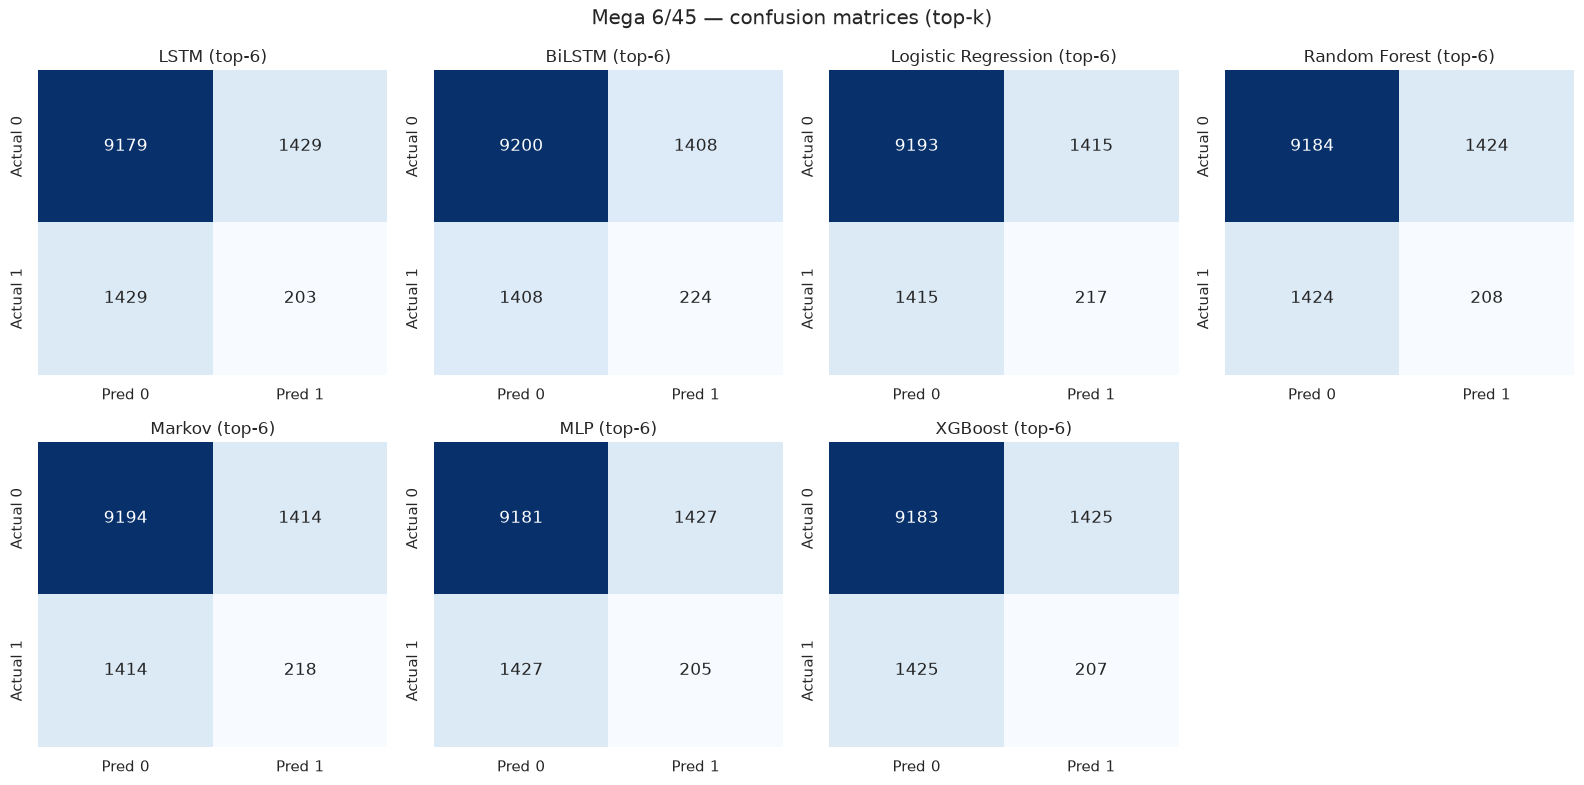

In [9]:
lottery = "mega645"
k = lottery_config(lottery)["pick"]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, name in zip(axes.ravel(), MODEL_NAMES, strict=False):
    pred = topk_prediction(PROBS[(lottery, name)], k)
    cm = binary_confusion(TRUTH[lottery], pred, 0.5).values
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Pred 0", "Pred 1"],
        yticklabels=["Actual 0", "Actual 1"],
        ax=ax,
    )
    ax.set_title(f"{DISPLAY_NAMES[name]} (top-{k})")
axes.ravel()[-1].axis("off")
fig.suptitle(f"{LOTTERIES[lottery]['name']} — confusion matrices (top-k)")
plt.tight_layout()
plt.show()

## 6. Precision / recall theo từng số

Gộp các kỳ test, tính precision/recall cho từng số (top-k). Nếu mô hình
không có thông tin thực, các giá trị này dao động quanh `k/F`.

In [10]:
def per_number_metrics(y_true, y_score, k: int) -> pd.DataFrame:
    y_true = np.asarray(y_true).astype(int)
    pred = topk_prediction(y_score, k)
    rows = []
    for j in range(y_true.shape[1]):
        t, p = y_true[:, j], pred[:, j]
        tp = int(((t == 1) & (p == 1)).sum())
        fp = int(((t == 0) & (p == 1)).sum())
        fn = int(((t == 1) & (p == 0)).sum())
        rows.append(
            {
                "number": j + 1,
                "actual_rate": t.mean(),
                "pred_rate": p.mean(),
                "precision": tp / (tp + fp) if tp + fp else 0.0,
                "recall": tp / (tp + fn) if tp + fn else 0.0,
                "tp": tp,
                "fp": fp,
                "fn": fn,
            }
        )
    return pd.DataFrame(rows)


lottery = "mega645"
k = lottery_config(lottery)["pick"]
for name in ["mlp", "logistic", "markov"]:
    df = per_number_metrics(TRUTH[lottery], PROBS[(lottery, name)], k)
    print(f"### {LOTTERIES[lottery]['name']} — {DISPLAY_NAMES[name]}")
    display(df.sort_values("precision", ascending=False).head(8).round(3))

### Mega 6/45 — MLP


,number,actual_rate,pred_rate,precision,recall,tp,fp,fn
29,30,0.158,0.085,0.261,0.140,6,17,37
21,22,0.162,0.121,0.182,0.136,6,27,38
43,44,0.151,0.335,0.176,0.390,16,75,25
15,16,0.151,0.397,0.157,0.415,17,91,24
25,26,0.147,0.048,0.154,0.050,2,11,38
19,20,0.151,0.301,0.146,0.293,12,70,29
23,24,0.129,0.357,0.144,0.400,14,83,21
17,18,0.118,0.077,0.143,0.094,3,18,29


### Mega 6/45 — Logistic Regression


,number,actual_rate,pred_rate,precision,recall,tp,fp,fn
6,7,0.147,0.004,1.000,0.025,1,0,39
44,45,0.176,0.018,0.200,0.021,1,4,47
9,10,0.140,0.415,0.186,0.553,21,92,17
1,2,0.140,0.099,0.185,0.132,5,22,33
22,23,0.129,0.022,0.167,0.029,1,5,34
33,34,0.121,0.092,0.160,0.121,4,21,29
32,33,0.096,0.419,0.158,0.692,18,96,8
35,36,0.165,0.283,0.156,0.267,12,65,33


### Mega 6/45 — Markov


,number,actual_rate,pred_rate,precision,recall,tp,fp,fn
12,13,0.132,0.015,0.500,0.056,2,2,34
39,40,0.096,0.011,0.333,0.038,1,2,25
0,1,0.110,0.059,0.250,0.133,4,12,26
27,28,0.169,0.015,0.250,0.022,1,3,45
22,23,0.129,0.015,0.250,0.029,1,3,34
19,20,0.151,0.232,0.206,0.317,13,50,28
17,18,0.118,0.055,0.200,0.094,3,12,29
43,44,0.151,0.371,0.188,0.463,19,82,22


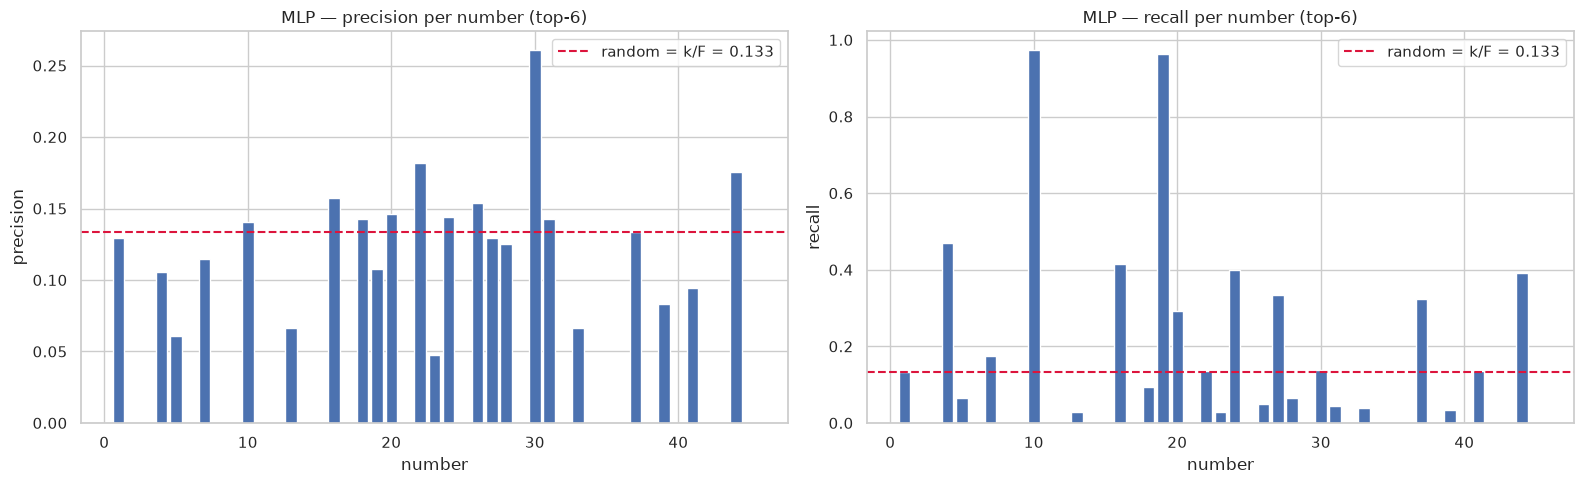

In [11]:
lottery = "mega645"
k = lottery_config(lottery)["pick"]
name = "mlp"
df = per_number_metrics(TRUTH[lottery], PROBS[(lottery, name)], k)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, col in zip(axes, ["precision", "recall"], strict=True):
    ax.bar(df["number"], df[col], color="#4c72b0")
    ax.axhline(
        k / lottery_config(lottery)["n_features"],
        color="crimson",
        linestyle="--",
        label=f"random = k/F = {k / lottery_config(lottery)['n_features']:.3f}",
    )
    ax.set_title(f"{DISPLAY_NAMES[name]} — {col} per number (top-{k})")
    ax.set_xlabel("number")
    ax.set_ylabel(col)
    ax.legend()
plt.tight_layout()
plt.show()

## 7. Quét ngưỡng xác suất

Với mỗi ngưỡng, xem precision/recall/F1 thay đổi thế nào. Ngưỡng tốt cho
F1 thường rất thấp vì xác suất nền nhỏ.

In [12]:
def threshold_sweep(y_true, y_score, thresholds=None) -> pd.DataFrame:
    if thresholds is None:
        thresholds = np.arange(0.05, 0.65, 0.05)
    rows = []
    for th in thresholds:
        m = confusion_metrics(binary_confusion(y_true, y_score, float(th)))
        rows.append({"threshold": round(float(th), 2), **m})
    return pd.DataFrame(rows)


lottery = "mega645"
for name in ["mlp", "logistic", "lstm"]:
    print(f"### {LOTTERIES[lottery]['name']} — {DISPLAY_NAMES[name]}")
    display(threshold_sweep(TRUTH[lottery], PROBS[(lottery, name)]).round(4))

### Mega 6/45 — MLP


,threshold,tp,fp,fn,tn,precision,recall,specificity,f1,accuracy
0,0.05,1632,10608,0,0,0.1333,1.0000,0.0000,0.2353,0.1333
1,0.10,1631,10604,1,4,0.1333,0.9994,0.0004,0.2352,0.1336
2,0.15,175,1058,1457,9550,0.1419,0.1072,0.9003,0.1222,0.7945
3,0.20,0,0,1632,10608,0.0000,0.0000,1.0000,0.0000,0.8667
4,0.25,0,0,1632,10608,0.0000,0.0000,1.0000,0.0000,0.8667
5,0.30,0,0,1632,10608,0.0000,0.0000,1.0000,0.0000,0.8667
6,0.35,0,0,1632,10608,0.0000,0.0000,1.0000,0.0000,0.8667
7,0.40,0,0,1632,10608,0.0000,0.0000,1.0000,0.0000,0.8667
8,0.45,0,0,1632,10608,0.0000,0.0000,1.0000,0.0000,0.8667
9,0.50,0,0,1632,10608,0.0000,0.0000,1.0000,0.0000,0.8667


### Mega 6/45 — Logistic Regression


,threshold,tp,fp,fn,tn,precision,recall,specificity,f1,accuracy
0,0.05,1632,10608,0,0,0.1333,1.0000,0.0000,0.2353,0.1333
1,0.10,1632,10608,0,0,0.1333,1.0000,0.0000,0.2353,0.1333
2,0.15,1632,10608,0,0,0.1333,1.0000,0.0000,0.2353,0.1333
3,0.20,1631,10605,1,3,0.1333,0.9994,0.0003,0.2352,0.1335
4,0.25,1622,10548,10,60,0.1333,0.9939,0.0057,0.2350,0.1374
5,0.30,1587,10299,45,309,0.1335,0.9724,0.0291,0.2348,0.1549
6,0.35,1539,9867,93,741,0.1349,0.9430,0.0699,0.2361,0.1863
7,0.40,1373,8850,259,1758,0.1343,0.8413,0.1657,0.2316,0.2558
8,0.45,1078,7119,554,3489,0.1315,0.6605,0.3289,0.2194,0.3731
9,0.50,716,4798,916,5810,0.1299,0.4387,0.5477,0.2004,0.5332


### Mega 6/45 — LSTM


,threshold,tp,fp,fn,tn,precision,recall,specificity,f1,accuracy
0,0.05,1632,10608,0,0,0.1333,1.000,0.0000,0.2353,0.1333
1,0.10,1632,10608,0,0,0.1333,1.000,0.0000,0.2353,0.1333
2,0.15,106,710,1526,9898,0.1299,0.065,0.9331,0.0866,0.8173
3,0.20,0,0,1632,10608,0.0000,0.000,1.0000,0.0000,0.8667
4,0.25,0,0,1632,10608,0.0000,0.000,1.0000,0.0000,0.8667
5,0.30,0,0,1632,10608,0.0000,0.000,1.0000,0.0000,0.8667
6,0.35,0,0,1632,10608,0.0000,0.000,1.0000,0.0000,0.8667
7,0.40,0,0,1632,10608,0.0000,0.000,1.0000,0.0000,0.8667
8,0.45,0,0,1632,10608,0.0000,0.000,1.0000,0.0000,0.8667
9,0.50,0,0,1632,10608,0.0000,0.000,1.0000,0.0000,0.8667


## 8. Ma trận nhầm lẫn lý thuyết của baseline ngẫu nhiên

Nếu chọn ngẫu nhiên `k` số mỗi kỳ, giá trị kỳ vọng của ma trận nhầm lẫn
(gộp toàn bộ kỳ test) là:

- `TP = n_test · k² / F`
- `FP = FN = n_test · k(F−k) / F`
- `TN = n_test · (F−k)² / F`

So sánh các bảng mô hình ở trên với mốc này để thấy chúng gần như trùng
khớp — phù hợp với bản chất ngẫu nhiên của xổ số.

In [13]:
rows = []
for lottery in LOTTERIES:
    cfg = lottery_config(lottery)
    data = prepared(lottery)
    n_test, f, k = len(data.test_targets), cfg["n_features"], cfg["pick"]
    tp = n_test * k * k / f
    fp = fn = n_test * k * (f - k) / f
    tn = n_test * (f - k) * (f - k) / f
    rows.append(
        {
            "lottery": cfg["name"],
            "n_test": n_test,
            "F": f,
            "k": k,
            "TP": round(tp, 1),
            "FP": round(fp, 1),
            "FN": round(fn, 1),
            "TN": round(tn, 1),
            "precision": round(k / f, 4),
            "recall": round(k / f, 4),
        }
    )
pd.DataFrame(rows)

,lottery,n_test,F,k,TP,FP,FN,TN,precision,recall
0,Mega 6/45,272,45,6,217.6,1414.4,1414.4,9193.6,0.1333,0.1333
1,Power 6/55,279,55,6,182.6,1491.4,1491.4,12179.6,0.1091,0.1091


## 9. Kết luận

- Ma trận nhầm lẫn theo top-k của các mô hình gần với baseline ngẫu nhiên.
  Precision/recall từng số dao động quanh `k/F`, không có số nào vượt
  trội ổn định.
- Ở ngưỡng 0.5, mô hình dự đoán gần như toàn âm do xác suất nền thấp;
  **không nên dùng accuracy** để kết luận.
- Chỉ số phù hợp: `avg_hits`, `lift`, `precision@k`, p-value so với kỳ
  vọng ngẫu nhiên (xem `reports/*_report.md`).
- Kết quả này là **trung thực**: xổ số ngẫu nhiên, mô hình không dự báo
  được kết quả thực tế. Giá trị của dự án nằm ở pipeline và quy trình
  đánh giá.